# MOP 3231 · Task 3 — Midterm Project: Will the Client Subscribe? (Bank Marketing)

**Student:** Imamsidikov · **Data:** `data/train.csv` (32,940 labelled calls) and `data/test.csv` (8,236 calls to score),
derived from UCI Bank Marketing (`bank-additional-full.csv`, CC BY 4.0)

| Part | Topic |
|---|---|
| 0 | Setup, versions, SEED |
| 1 | Loading and checking the data |
| 2 | EDA: the target and the numeric features |
| 3 | EDA: the categorical features, `unknown`, `pdays = 999` and `duration` |
| 4 | Validation split and the preprocessing pipeline |
| 5 | Baselines and stronger models |
| 6 | Cross-validation and tuning |
| 7 | Final evaluation and threshold |
| 8 | Refit, save, reload and score `test.csv` |

This is a teaching dataset, not evidence about real banks or clients.

## Part 0 · Setup

Virtual environment `.Imamsidikov_ML_task_3` (Python 3.12) with the pinned `requirements.txt`; Jupyter is only the tool
and stays out of it.

**SEED = 2954**: the last four digits of my student ID (S24072954). It seeds every split, fold and model.

In [1]:
import sys

import joblib
import matplotlib
import numpy
import pandas
import scipy
import sklearn

print(sys.version.split()[0], numpy.__version__, scipy.__version__, pandas.__version__,
      matplotlib.__version__, sklearn.__version__, joblib.__version__)

3.12.12 2.3.4 1.16.3 2.3.3 3.10.7 1.7.2 1.5.2


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 2954
TARGET = "y"

# Chart style: recessive grid and axes, one colour per class used the same way in every figure
NO, YES, NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 11,
    "axes.grid": True,
    "grid.color": "#e7e6e1",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})

## Part 1 · Loading and checking the data

In [3]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("train:", train.shape, "| test:", test.shape)
print("in train only:", sorted(set(train.columns) - set(test.columns)))
print("in test only: ", sorted(set(test.columns) - set(train.columns)))

train: (32940, 22) | test: (8236, 20)
in train only: ['duration', 'y']
in test only:  []


In [4]:
# Column types and the values seen in train
summary = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "missing": train.isna().sum(),
    "example": train.iloc[0],
})
summary

,dtype,n_unique,missing,example
id,int64,32940,0,0
age,int64,76,0,39
job,object,12,0,management
marital,object,4,0,single
education,object,8,0,basic.9y
default,object,3,0,unknown
housing,object,3,0,yes
loan,object,3,0,no
contact,object,2,0,telephone
month,object,10,0,may


In [5]:
checks = {
    "missing cells in train": int(train.isna().sum().sum()),
    "missing cells in test": int(test.isna().sum().sum()),
    "train ids unique": train["id"].is_unique,
    "test ids unique": test["id"].is_unique,
    "train and test ids disjoint": set(train["id"]).isdisjoint(test["id"]),
    "duplicate rows in train (ignoring id)": int(train.drop(columns="id").duplicated().sum()),
    "target values": sorted(train[TARGET].unique()),
}
for name, value in checks.items():
    print(f"{name:40s} {value}")

missing cells in train                   0
missing cells in test                    0
train ids unique                         True
test ids unique                          True
train and test ids disjoint              True
duplicate rows in train (ignoring id)    0
target values                            ['no', 'yes']


In [6]:
# Same categories in train and test? A level seen only in test would need handle_unknown in the encoder.
categorical = [c for c in test.columns if test[c].dtype == object]
numeric = [c for c in test.columns if c not in categorical and c != "id"]
for c in categorical:
    only_test = set(test[c]) - set(train[c])
    if only_test:
        print(c, "levels only in test:", only_test)
print(len(categorical), "categorical:", categorical)
print(len(numeric), "numeric:", numeric)

10 categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
9 numeric: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


**What the checks say**

- No missing cells (`NaN`) in either file, unique and disjoint `id`s, no duplicate rows. Missing information is coded
  as values instead: the string `unknown` in six categorical columns and `pdays = 999` (Part 3).
- `train.csv` has two columns `test.csv` lacks: the target `y` and `duration`. A model can only use what `test.csv`
  has, so the feature set is the 19 columns of `test.csv` minus `id`: 10 categorical and 9 numeric.
- `id` is a shuffled row number added when the files were made. It carries no information and is not a feature.

## Part 2 · EDA: the target and the numeric features

### The target

In [7]:
y_counts = train[TARGET].value_counts()
yes_rate = (train[TARGET] == "yes").mean()
print(y_counts.to_string())
print(f"subscription rate: {yes_rate:.3f}  (about 1 in {1 / yes_rate:.0f} calls)")
print(f"accuracy of always answering 'no': {1 - yes_rate:.3f}")

y
no     29229
yes     3711
subscription rate: 0.113  (about 1 in 9 calls)
accuracy of always answering 'no': 0.887


**The business question.** The bank wants to know, before it picks up the phone, which clients are worth calling
about a term deposit. Its call centre can only call **10 % of the clients** on the list, so the model's job is to put
the clients most likely to say `yes` at the top of that list, and the final cutoff is set so that 10 % are called
(Part 7). Success is measured by how many subscribers are found within those calls.

About 11 % of calls end in a subscription. The classes are imbalanced, so **accuracy is a weak metric** here: the
useless model that always says "no" already scores about 0.89. Models will be compared on metrics that look at the
`yes` class: **average precision** (main metric: it rewards putting `yes` clients at the top of the list, which is
exactly what a 10 % call budget needs), ROC AUC, and precision and recall of `yes`. Every split and fold will be
**stratified** on `y` so each part keeps the 11 % rate.

### Numeric features

In [8]:
train[numeric].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32940.0,40.04,10.43,17.00,32.00,38.00,47.00,98.00
campaign,32940.0,2.55,2.73,1.00,1.00,2.00,3.00,56.00
pdays,32940.0,961.44,189.46,0.00,999.00,999.00,999.00,999.00
previous,32940.0,0.17,0.50,0.00,0.00,0.00,0.00,7.00
emp.var.rate,32940.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,32940.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,32940.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,32940.0,3.62,1.74,0.63,1.34,4.86,4.96,5.04
nr.employed,32940.0,5167.03,72.39,4963.60,5099.10,5191.00,5228.10,5228.10


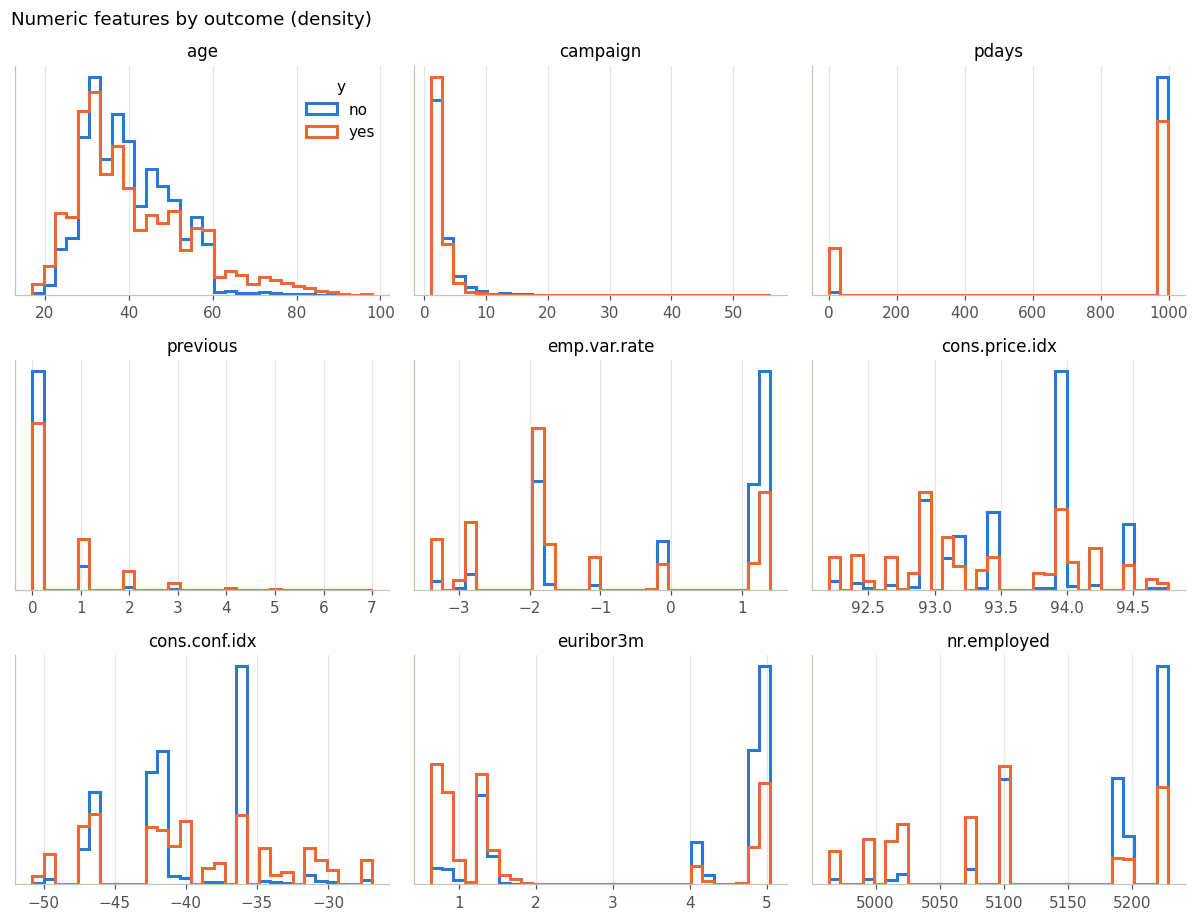

In [9]:
# Distribution of each numeric feature by class (densities, so the small 'yes' class is visible)
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5))
for ax, col in zip(axes.flat, numeric):
    values = train[col]
    bins = np.histogram_bin_edges(values, bins=30)
    for label, color in (("no", NO), ("yes", YES)):
        ax.hist(values[train[TARGET] == label], bins=bins, density=True, histtype="step",
                linewidth=2, color=color, label=label)
    ax.set_title(col)
    ax.set_yticks([])
axes.flat[0].legend(title="y")
fig.suptitle("Numeric features by outcome (density)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [10]:
# Medians by class, and how skewed / concentrated each column is
by_class = train.groupby(TARGET)[numeric].median().T
by_class["share of most common value"] = [train[c].value_counts(normalize=True).iloc[0] for c in numeric]
by_class["skew"] = train[numeric].skew()
by_class.round(3)

y,no,yes,share of most common value,skew
age,38.000,37.000,0.047,0.776
campaign,2.000,2.000,0.428,4.779
pdays,999.000,999.000,0.962,-4.846
previous,0.000,0.000,0.864,3.850
emp.var.rate,1.100,-1.800,0.396,-0.726
cons.price.idx,93.918,93.200,0.187,-0.235
cons.conf.idx,-41.800,-40.300,0.187,0.303
euribor3m,4.857,1.266,0.069,-0.710
nr.employed,5195.800,5099.100,0.396,-1.044


In [11]:
# The five economic indicators are monthly/quarterly series, so they move together
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print("distinct values:", train[macro].nunique().to_dict())
train[macro].corr().round(2)

distinct values: {'emp.var.rate': 10, 'cons.price.idx': 26, 'cons.conf.idx': 26, 'euribor3m': 316, 'nr.employed': 11}


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.78,0.19,0.97,0.91
cons.price.idx,0.78,1.00,0.05,0.69,0.52
cons.conf.idx,0.19,0.05,1.00,0.27,0.10
euribor3m,0.97,0.69,0.27,1.00,0.95
nr.employed,0.91,0.52,0.10,0.95,1.00


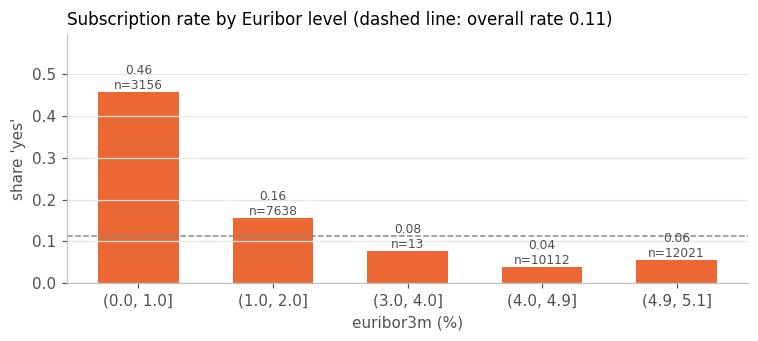

In [12]:
# Subscription rate across the range of the 3-month Euribor rate
bins = pd.cut(train["euribor3m"], bins=[0, 1, 2, 3, 4, 4.9, 5.1])
rate = train.groupby(bins, observed=True)[TARGET].apply(lambda s: (s == "yes").mean())
count = bins.value_counts().reindex(rate.index)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(rate.index.astype(str), rate.values, width=0.6, color=YES)
ax.axhline(yes_rate, color=NEUTRAL, linewidth=1, linestyle="--")
for i, (r, n) in enumerate(zip(rate.values, count.values)):
    ax.text(i, r, f"{r:.2f}\nn={n}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_xlabel("euribor3m (%)")
ax.set_ylabel("share 'yes'")
ax.set_ylim(0, rate.max() * 1.3)
ax.grid(axis="x", visible=False)
ax.set_title(f"Subscription rate by Euribor level (dashed line: overall rate {yes_rate:.2f})", loc="left")
fig.tight_layout()
plt.show()

**What the numeric features say**

- **The economic indicators carry the strongest numeric signal.** Median `euribor3m` is 4.86 for `no` and 1.27 for
  `yes`; below 1 % the subscription rate is 0.46, above 4 % it is 0.04–0.06. `emp.var.rate` and `nr.employed` show the
  same split. These columns have very few distinct values (10 for `emp.var.rate`, 11 for `nr.employed`) because they
  are monthly or quarterly figures: they record *when* the call was made, so they act as a marker of the campaign
  period as much as of the economy.
- `emp.var.rate`, `euribor3m` and `nr.employed` are almost the same variable (correlations 0.91–0.97). That does not
  hurt prediction, but it makes the individual coefficients of a linear model unstable, so I will not read meaning
  into them one by one. Regularisation (the default in `LogisticRegression`) keeps them in check.
- `age`: `yes` is more common at both ends: 0.24 for clients up to 24 and 0.46 over 60, against 0.08–0.11 between 30
  and 60. The relation is not monotonic, which a tree can pick up but a linear model only partly can.
- `campaign` (calls in this campaign) is very right-skewed (skew 4.8, maximum 56) and the rate falls as calls pile up:
  0.13 after one call, 0.06 after six or more.
- `previous` is 0 for 86 % of clients, but the rate climbs with it: 0.09 at 0, 0.21 at 1, 0.46 at 2.
- `pdays` is 999 in 96 % of rows; it is handled in Part 3.
- Scales differ by orders of magnitude (`nr.employed` ≈ 5,000, `cons.price.idx` ≈ 93, `euribor3m` ≈ 1–5), so
  scale-sensitive models (logistic regression, k-NN, SVM) need the numeric columns standardised. Trees do not.

## Part 3 · EDA: categorical features, `unknown`, `pdays = 999` and `duration`

### Subscription rate by category

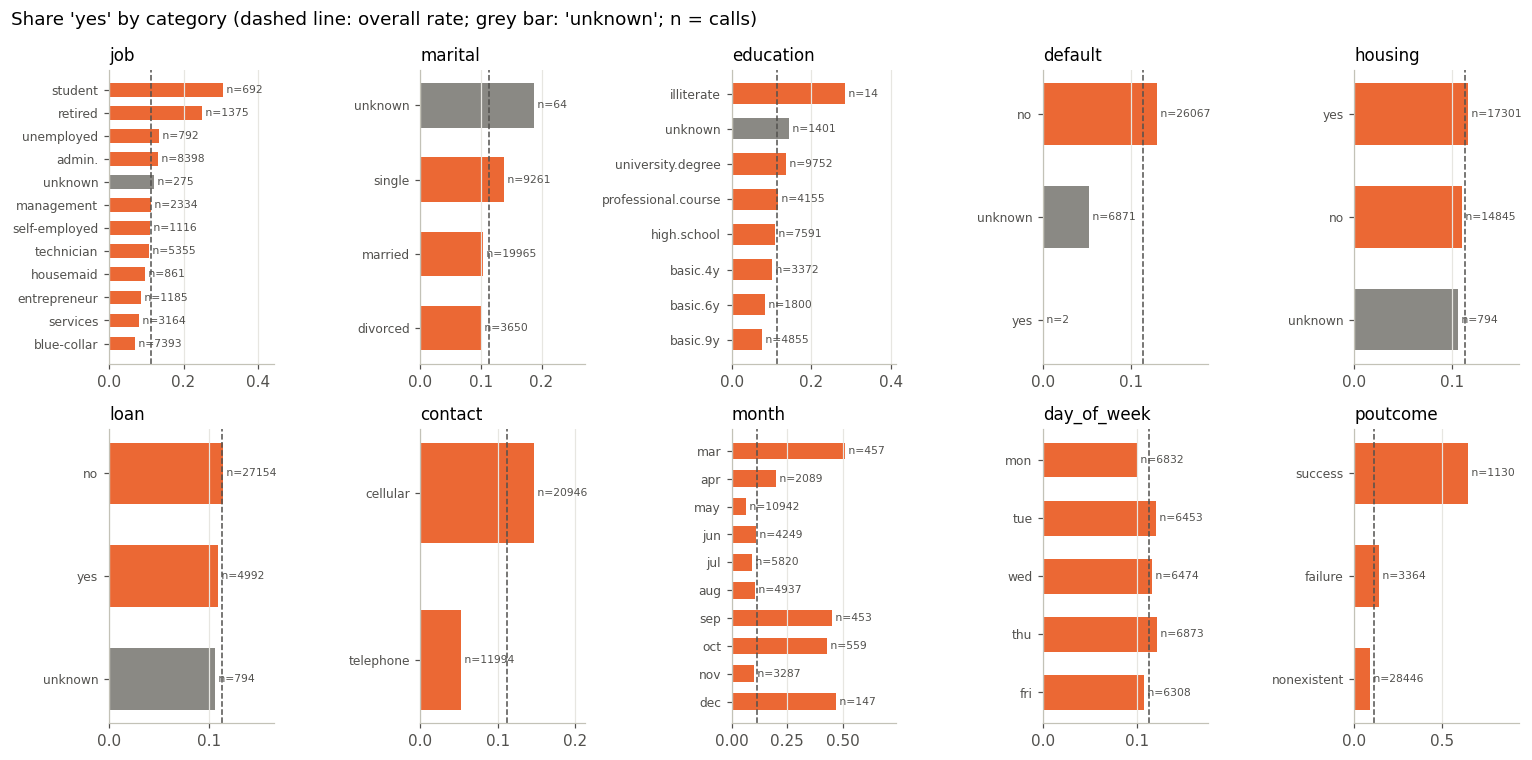

In [13]:
def yes_rate_by(col):
    g = train.groupby(col)[TARGET]
    return pd.DataFrame({"n": g.size(), "yes_rate": g.apply(lambda s: (s == "yes").mean())})


month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
day_order = ["mon", "tue", "wed", "thu", "fri"]

fig, axes = plt.subplots(2, 5, figsize=(14, 7))
for ax, col in zip(axes.flat, categorical):
    t = yes_rate_by(col)
    if col == "month":
        t = t.reindex(month_order)
    elif col == "day_of_week":
        t = t.reindex(day_order)
    else:
        t = t.sort_values("yes_rate")
    colors = [NEUTRAL if level == "unknown" else YES for level in t.index]
    ax.barh(t.index, t["yes_rate"], height=0.6, color=colors)
    for level, row in t.iterrows():
        ax.text(row["yes_rate"], level, f" n={row['n']:.0f}", va="center", fontsize=7, color="#52514e")
    ax.set_xlim(0, t["yes_rate"].max() * 1.45)
    ax.axvline(yes_rate, color="#52514e", linewidth=1, linestyle="--")
    ax.set_title(col, loc="left")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
    if col in ("month", "day_of_week"):
        ax.invert_yaxis()
fig.suptitle("Share 'yes' by category (dashed line: overall rate; grey bar: 'unknown'; n = calls)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [14]:
# The categories with the highest and lowest rates (only levels with at least 100 calls)
rows = []
for col in categorical:
    t = yes_rate_by(col)
    t = t[t["n"] >= 100]
    rows.append({"feature": col, "lowest": f"{t['yes_rate'].idxmin()} ({t['yes_rate'].min():.3f})",
                 "highest": f"{t['yes_rate'].idxmax()} ({t['yes_rate'].max():.3f})",
                 "spread": t["yes_rate"].max() - t["yes_rate"].min()})
pd.DataFrame(rows).sort_values("spread", ascending=False).round(3)

,feature,lowest,highest,spread
9,poutcome,nonexistent (0.088),success (0.648),0.560
7,month,may (0.064),mar (0.512),0.449
0,job,blue-collar (0.070),student (0.305),0.235
6,contact,telephone (0.053),cellular (0.147),0.094
3,default,unknown (0.052),no (0.129),0.077
2,education,basic.9y (0.077),unknown (0.144),0.067
1,marital,divorced (0.101),single (0.138),0.038
8,day_of_week,mon (0.100),thu (0.121),0.021
4,housing,unknown (0.106),yes (0.116),0.010
5,loan,unknown (0.106),no (0.114),0.008


### `unknown` values

In [15]:
unknown = pd.DataFrame({
    "unknown_train": (train[categorical] == "unknown").sum(),
    "unknown_test": (test[categorical] == "unknown").sum(),
})
unknown["share_train"] = unknown["unknown_train"] / len(train)
unknown["yes_rate_when_unknown"] = [
    (train.loc[train[c] == "unknown", TARGET] == "yes").mean() if n else np.nan
    for c, n in unknown["unknown_train"].items()
]
unknown = unknown[unknown["unknown_train"] > 0]
print("rows with at least one 'unknown':", int((train[categorical] == "unknown").any(axis=1).sum()))
unknown.round(3)

rows with at least one 'unknown': 8582


,unknown_train,unknown_test,share_train,yes_rate_when_unknown
job,275,55,0.008,0.120
marital,64,16,0.002,0.188
education,1401,329,0.043,0.144
default,6871,1725,0.209,0.052
housing,794,196,0.024,0.106
loan,794,196,0.024,0.106


In [16]:
# 'default' is almost a constant once 'unknown' is set aside; housing and loan are unknown on the same rows
print(train["default"].value_counts().to_string(), end="\n\n")
print("housing unknown == loan unknown on every row:",
      ((train["housing"] == "unknown") == (train["loan"] == "unknown")).all())

default
no         26067
unknown     6871
yes            2

housing unknown == loan unknown on every row: True


### `pdays = 999`, `previous` and `poutcome`

`pdays` is the number of days since the client was last contacted in an earlier campaign; the UCI description says
`999` means *not previously contacted*. It is a code, not a number of days: left as is, a linear model would read it as
"999 days ago", far beyond the real values (0 to 25).

In [17]:
never = train["pdays"] == 999
print(f"pdays == 999: {never.mean():.3f} of train | {(test['pdays'] == 999).mean():.3f} of test")
print("real pdays values:", sorted(train.loc[~never, "pdays"].unique().tolist()))
print()
print(pd.crosstab([never.rename("pdays == 999"), train["poutcome"]], train[TARGET], margins=True))

pdays == 999: 0.962 of train | 0.967 of test
real pdays values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 25]

y                            no   yes    All
pdays == 999 poutcome                       
False        failure         55    61    116
             success        398   732   1130
True         failure       2837   411   3248
             nonexistent  25939  2507  28446
All                       29229  3711  32940


In [18]:
print(pd.crosstab(train["previous"], train["poutcome"]))
print()
print(yes_rate_by(never.map({True: "pdays == 999", False: "pdays has a value"})).round(3))

poutcome  failure  nonexistent  success
previous                               
0               0        28446        0
1            2914            0      712
2             355            0      258
3              72            0      107
4              20            0       35
5               2            0       14
6               1            0        3
7               0            0        1

                       n  yes_rate
pdays                             
pdays == 999       31694     0.092
pdays has a value   1246     0.636


### `duration`

In [19]:
print(train.groupby(TARGET)["duration"].describe().round(1))
print()
print("calls with duration == 0:", int((train["duration"] == 0).sum()),
      "| their outcomes:", train.loc[train["duration"] == 0, TARGET].value_counts().to_dict())

       count   mean    std   min    25%    50%    75%     max
y                                                            
no   29229.0  220.3  204.2   0.0   95.0  164.0  278.0  3509.0
yes   3711.0  552.2  399.9  37.0  253.0  449.0  739.5  4199.0

calls with duration == 0: 2 | their outcomes: {'no': 2}


**What Parts 1–3 decide for the pipeline**

- **`duration` is dropped.** Calls that end in `yes` last much longer (median 449 s against 164 s), and a call of
  length 0 is always `no`, but the length of a call is only known *after* the call, when the answer is known too.
  Using it would leak the outcome into the features, and `test.csv` does not have it anyway.
- **`id` is dropped**; it is a shuffled row number.
- **`unknown` stays as its own category** and is one-hot encoded like any other level. 8,582 training rows (26 %)
  have at least one `unknown`, so dropping them would throw away a quarter of the data, and the `unknown` is
  informative: clients with `default = unknown` subscribe at 0.052, against 0.129 for `default = no`. Imputing the
  most frequent level would erase that difference. `default = yes` occurs in only 2 rows, so `default` is in
  practice "no" against "unknown".
- **`pdays = 999` is a code.** In the pipeline it becomes a flag `pdays_contacted` (1 when `pdays` has a real value)
  plus `pdays` with 999 replaced by −1, so no scaler or linear model treats it as 999 days. The flag matters: the rate
  is 0.636 when `pdays` has a value and 0.092 when it is 999. `pdays = 999` does not strictly mean *never contacted*:
  3,248 rows have 999 but `poutcome = failure` and `previous > 0`, so `previous` and `poutcome` are kept as features
  next to the flag.
- **Strong categorical features:** `poutcome` (`success` 0.648 against 0.088 for `nonexistent`), `month` (`may`, the
  busiest month with 10,942 calls, has 0.064; the small months `mar`, `sep`, `oct`, `dec` have 0.43–0.51), `contact`
  (`cellular` 0.147, `telephone` 0.053) and `job` (`student` 0.305, `retired` 0.250, `blue-collar` 0.070).
  `housing`, `loan` and `day_of_week` barely move the rate (spread ≤ 0.02) and are expected to add little.
- Some levels are tiny (`education = illiterate`: 14 rows, `marital = unknown`: 64), so their extreme rates are noisy.
  The encoder is set to ignore levels it has not seen in training, in case a fold or `test.csv` meets one.
- **Imbalance:** 11 % `yes`, so stratified splits and folds, and metrics built around the `yes` class rather than
  accuracy.

## Part 4 · Validation split and the preprocessing pipeline

### Features, target and the hold-out set

`test.csv` has no labels, so the only way to measure a model on unseen data is to set part of `train.csv` aside.

- **Development set (80 %)**: all model comparison, cross-validation and tuning happen here, with the same 5 stratified
  folds for every model so the scores are comparable.
- **Hold-out set (20 %)**: not touched until Part 7, where the one chosen model is scored on it once. Looking at it
  earlier would turn it into one more tuning set and its score would be optimistic.

The features are the 19 columns `test.csv` has, minus `id`; `duration` is dropped (Part 3). The target is 1 for `yes`.

In [20]:
from sklearn.model_selection import StratifiedKFold, train_test_split

FEATURES = [c for c in test.columns if c != "id"]
X = train[FEATURES]
y = (train[TARGET] == "yes").astype(int)
X_test = test[FEATURES]

X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("features:", len(FEATURES), "| 'duration' in features:", "duration" in FEATURES)
print(f"development {X_dev.shape}, yes rate {y_dev.mean():.4f}")
print(f"hold-out    {X_hold.shape}, yes rate {y_hold.mean():.4f}")
print("yes rate in each validation fold:",
      [round(float(y_dev.iloc[val].mean()), 4) for _, val in cv.split(X_dev, y_dev)])

features: 19 | 'duration' in features: False
development (26352, 19), yes rate 0.1127
hold-out    (6588, 19), yes rate 0.1126
yes rate in each validation fold: [0.1127, 0.1127, 0.1125, 0.1127, 0.1127]


### The preprocessing pipeline

The decisions of Part 3 as one `ColumnTransformer`:

| Columns | Steps |
|---|---|
| `pdays` | 999 replaced by −1 (`SimpleImputer(missing_values=999)`), then standardised |
| `pdays` again | `MissingIndicator(missing_values=999)`: a 0/1 column `pdays = 999`, the flag of Part 3 (1 when *not* contacted, the complement of `pdays_contacted`) |
| the other 8 numeric | standardised |
| the 10 categorical | one-hot; `unknown` is a level like any other; levels unseen in training are ignored |

Two reasons it is built this way:

1. It goes **inside** a `Pipeline` with the model, so in cross-validation the scaler means and the one-hot levels are
   learned on the training folds only, never on the fold being scored.
2. It uses **only scikit-learn classes**, no function written in this notebook. A pipeline that called a notebook
   function could not be loaded with `joblib` in a fresh session that does not have that function; this one only
   needs the pinned libraries.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_rest = [c for c in numeric if c != "pdays"]


def make_preprocessor():
    return ColumnTransformer([
        ("pdays", make_pipeline(SimpleImputer(missing_values=999, strategy="constant", fill_value=-1),
                                StandardScaler()), ["pdays"]),
        ("pdays_999", MissingIndicator(missing_values=999, features="all"), ["pdays"]),
        ("num", StandardScaler(), numeric_rest),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ])


def make_pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])


prep = make_preprocessor().fit(X_dev)
Z = pd.DataFrame(prep.transform(X_dev), columns=prep.get_feature_names_out(), index=X_dev.index)
print("columns after preprocessing:", Z.shape[1], "| any NaN:", bool(Z.isna().any().any()))
print("one-hot columns per feature:",
      {c: len(levels) for c, levels in zip(categorical, prep.named_transformers_["cat"].categories_)})

columns after preprocessing: 63 | any NaN: False
one-hot columns per feature: {'job': 12, 'marital': 4, 'education': 8, 'default': 3, 'housing': 3, 'loan': 3, 'contact': 2, 'month': 10, 'day_of_week': 5, 'poutcome': 3}


In [22]:
# What happens to pdays: three rows with a real value and three with 999
sample = pd.concat([X_dev[X_dev["pdays"] != 999].head(3), X_dev[X_dev["pdays"] == 999].head(3)])
pd.DataFrame({
    "pdays (raw)": sample["pdays"],
    "pdays (999 -> -1, scaled)": Z.loc[sample.index, "pdays__pdays"].round(3),
    "pdays = 999 flag": Z.loc[sample.index, "pdays_999__missingindicator_pdays"].astype(int),
})

,pdays (raw),"pdays (999 -> -1, scaled)",pdays = 999 flag
22941,3,2.493,0
13747,4,3.160,0
2998,6,4.493,0
11738,999,-0.175,1
21039,999,-0.175,1
12208,999,-0.175,1


In [23]:
# Every numeric column now has mean 0 and standard deviation 1 on the data it was fitted on
Z[[c for c in Z.columns if c.startswith(("num__", "pdays__"))]].agg(["mean", "std"]).round(3)

,pdays__pdays,num__age,num__campaign,num__previous,num__emp.var.rate,num__cons.price.idx,num__cons.conf.idx,num__euribor3m,num__nr.employed
mean,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Part 5 · Baselines and stronger models

### How models are compared

All models are scored with the same 5 folds of the development set. Because `yes` is rare (Part 2), the main metrics
look at how well a model **ranks** clients by their chance of saying `yes`, without fixing a threshold:

- **Average precision (AP)**, the area under the precision–recall curve. It is the main metric: it rewards finding
  the `yes` clients near the top of the list, which is what a call campaign needs. A model that guesses scores
  the base rate, 0.113.
- **ROC AUC**: the chance that a random `yes` client gets a higher score than a random `no` client (0.5 = guessing).

Precision, recall and F1 of `yes` at the default threshold 0.5 are reported too. They depend on the threshold, which is
chosen in Part 7.

In [24]:
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import cross_validate

SCORING = {
    "avg_precision": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score),
    "f1": make_scorer(f1_score),
    "accuracy": "accuracy",
}
cv_results = {}


def evaluate(name, model):
    """5-fold CV of preprocessor + model on the development set; stores and returns the per-fold scores."""
    scores = cross_validate(make_pipe(model), X_dev, y_dev, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_results[name] = pd.DataFrame({m: scores[f"test_{m}"] for m in SCORING} | {"fit_s": scores["fit_time"]})
    return cv_results[name]


def cv_table(names=None):
    names = names or list(cv_results)
    rows = {}
    for name in names:
        s = cv_results[name]
        rows[name] = {"AP": s["avg_precision"].mean(), "AP sd": s["avg_precision"].std(),
                      "ROC AUC": s["roc_auc"].mean(), "ROC AUC sd": s["roc_auc"].std(),
                      "precision@0.5": s["precision"].mean(), "recall@0.5": s["recall"].mean(),
                      "F1@0.5": s["f1"].mean(), "accuracy": s["accuracy"].mean(), "fit s": s["fit_s"].mean()}
    return pd.DataFrame(rows).T.round(3)

### Baselines

- `DummyClassifier`: predicts the training base rate for everyone. Any real model has to beat it.
- Logistic regression with default settings (`C = 1`, L2 penalty).
- The same with `class_weight="balanced"`, which weights each `yes` about 8 times more than each `no` in the loss.

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

evaluate("dummy (prior)", DummyClassifier(strategy="prior"))
evaluate("logistic", LogisticRegression(max_iter=2000))
evaluate("logistic, balanced", LogisticRegression(max_iter=2000, class_weight="balanced"))
cv_table()

,AP,AP sd,ROC AUC,ROC AUC sd,precision@0.5,recall@0.5,F1@0.5,accuracy,fit s
dummy (prior),0.113,0.000,0.500,0.000,0.000,0.000,0.000,0.887,0.058
logistic,0.457,0.022,0.794,0.011,0.662,0.245,0.358,0.901,0.174
"logistic, balanced",0.454,0.022,0.795,0.013,0.364,0.631,0.462,0.834,0.393


In [26]:
# Which features does the logistic regression lean on? (largest absolute coefficients on standardised features)
logit = make_pipe(LogisticRegression(max_iter=2000)).fit(X_dev, y_dev)
coef = pd.Series(logit[-1].coef_[0], index=logit[0].get_feature_names_out())
coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(3)

num__emp.var.rate                   -2.220
cat__month_mar                       1.349
pdays_999__missingindicator_pdays   -1.193
num__cons.price.idx                  1.172
cat__month_jun                      -0.718
cat__month_nov                      -0.578
cat__month_may                      -0.539
cat__contact_telephone              -0.510
cat__poutcome_failure               -0.509
cat__education_illiterate            0.489
cat__marital_unknown                 0.405
num__nr.employed                     0.371
dtype: float64

**What the baselines say**

- Logistic regression is far above the dummy: AP 0.457 against 0.113, ROC AUC 0.794 against 0.5. The features
  available before the call do carry signal.
- **Accuracy hides the problem.** The plain logistic regression reaches 0.901 accuracy, only 0.014 above "always no",
  and at the 0.5 threshold it finds only 25 % of the `yes` clients (recall 0.245).
- `class_weight="balanced"` leaves the ranking almost unchanged (AP 0.454, ROC AUC 0.795) but moves the operating
  point: recall rises to 0.63 and precision falls from 0.66 to 0.36. Weighting the classes acts like lowering the
  threshold; it does not make the model better at telling clients apart. The threshold itself is set in Part 7.
- The coefficients repeat the EDA: the economic period (`emp.var.rate`, `cons.price.idx`), the month, the
  `pdays = 999` flag (−1.19: not contacted recently lowers the odds) and `contact = telephone`. `nr.employed` gets a
  *positive* coefficient (+0.37) although its relation with `yes` is negative on its own (Part 2). That is the collinearity
  warned about in Part 2: with `emp.var.rate` and `euribor3m` in the model, the sign of `nr.employed` is not
  interpretable.

### One preprocessing choice against its alternative

Part 3 kept `unknown` as its own category. The usual alternative is to replace it with the most frequent level of its
column. Same model (plain logistic regression), same 5 folds; only the categorical step of the preprocessor changes.

In [27]:
# Alternative: 'unknown' replaced by the most frequent level of its column before one-hot encoding
alt_pipe = make_pipe(LogisticRegression(max_iter=2000)).set_params(
    prep__cat=make_pipeline(SimpleImputer(missing_values="unknown", strategy="most_frequent"),
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
alt = cross_validate(alt_pipe, X_dev, y_dev, cv=cv, scoring={"AP": "average_precision", "ROC AUC": "roc_auc"},
                     n_jobs=-1)
own = cv_results["logistic"]

diff = own["avg_precision"].to_numpy() - alt["test_AP"]
print(f"AP per fold, own level minus imputed: {np.round(diff, 4).tolist()}, mean {diff.mean():+.4f}, "
      f"folds won {(diff > 0).sum()}/5")
pd.DataFrame({
    "'unknown' as its own level (used)": {"AP": own["avg_precision"].mean(), "AP sd": own["avg_precision"].std(),
                                          "ROC AUC": own["roc_auc"].mean(), "ROC AUC sd": own["roc_auc"].std()},
    "'unknown' -> most frequent level": {"AP": alt["test_AP"].mean(), "AP sd": alt["test_AP"].std(ddof=1),
                                         "ROC AUC": alt["test_ROC AUC"].mean(),
                                         "ROC AUC sd": alt["test_ROC AUC"].std(ddof=1)},
}).T.round(4)

AP per fold, own level minus imputed: [0.0006, -0.0003, 0.0015, -0.0005, -0.0012], mean +0.0000, folds won 2/5


,AP,AP sd,ROC AUC,ROC AUC sd
'unknown' as its own level (used),0.4573,0.0223,0.7941,0.0105
'unknown' -> most frequent level,0.4572,0.0219,0.7946,0.0115


**What the comparison says:** keeping `unknown` as its own level and replacing it by the most frequent level give the
same AP (0.4573 against 0.4572, ROC AUC 0.794 against 0.795). The per-fold differences are below 0.002 and go both
ways (2 of 5 folds), far inside the fold spread of 0.02. So the choice does not change the score. I keep `unknown` as
its own level because it does not cost anything and keeps the information that the value was missing, which Part 3
showed is related to `y` (`default = unknown`: 0.052 against 0.129).

### Stronger models

Tree-based models can capture what logistic regression cannot without extra features: the U-shape of `age`, the
steps in the economic indicators, and interactions such as month × contact type. All three use the same preprocessor
(scaling does not change a tree, so it is harmless) and the same folds:

- a single decision tree, depth limited to 6 so it does not memorise the training folds;
- a random forest of 300 trees with leaves of at least 5 rows;
- histogram gradient boosting with default settings (early stopping on an internal 10 % of each training fold).

In [28]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

evaluate("decision tree (depth 6)", DecisionTreeClassifier(max_depth=6, random_state=SEED))
evaluate("random forest", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED))
evaluate("gradient boosting", HistGradientBoostingClassifier(random_state=SEED))
cv_table()

,AP,AP sd,ROC AUC,ROC AUC sd,precision@0.5,recall@0.5,F1@0.5,accuracy,fit s
dummy (prior),0.113,0.000,0.500,0.000,0.000,0.000,0.000,0.887,0.058
logistic,0.457,0.022,0.794,0.011,0.662,0.245,0.358,0.901,0.174
"logistic, balanced",0.454,0.022,0.795,0.013,0.364,0.631,0.462,0.834,0.393
decision tree (depth 6),0.428,0.024,0.785,0.010,0.647,0.260,0.370,0.901,0.111
random forest,0.476,0.022,0.798,0.011,0.665,0.264,0.377,0.902,3.590
gradient boosting,0.476,0.019,0.803,0.014,0.648,0.267,0.378,0.901,0.543


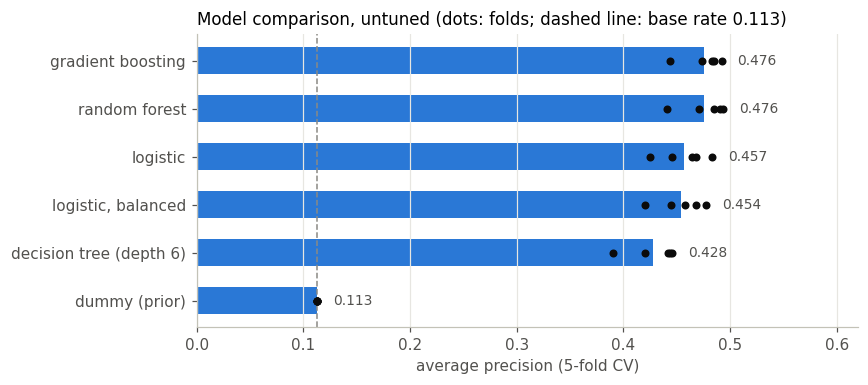

In [29]:
# Average precision of every model on each of the 5 folds (dots) and the mean (bar)
table = cv_table().sort_values("AP")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(table.index, table["AP"], height=0.55, color=NO)
for i, name in enumerate(table.index):
    ax.scatter(cv_results[name]["avg_precision"], [i] * 5, s=18, color="#0b0b0b", zorder=3)
    ax.text(cv_results[name]["avg_precision"].max() + 0.015, i, f"{table.loc[name, 'AP']:.3f}", va="center", fontsize=9,
            color="#52514e")
ax.axvline(y_dev.mean(), color=NEUTRAL, linewidth=1, linestyle="--")
ax.set_xlim(0, 0.62)
ax.set_xlabel("average precision (5-fold CV)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Model comparison, untuned (dots: folds; dashed line: base rate {y_dev.mean():.3f})", loc="left")
fig.tight_layout()
plt.show()

**What the stronger models say**

- Random forest and gradient boosting are the best untuned models (AP 0.476 both, ROC AUC 0.798 and 0.803), about
  0.02 AP above logistic regression. The single depth-6 tree is the weakest real model (0.428): one tree is too coarse
  and too unstable compared with an ensemble of many.
- The fold-to-fold spread (dots) is about ±0.02 AP for every model, about the size of the gap between the families,
  so a single split could have ranked them differently. That is why every model is scored on the same 5 folds and the
  comparison in Part 6 is made fold by fold.
- Gradient boosting fits in about 0.5 s per fold, the forest in about 3.3 s, for the same AP. It is the family
  worth tuning, next to logistic regression as the simpler alternative.

## Part 6 · Cross-validation and tuning

The two best families of Part 5 are tuned on the same 5 folds, with **average precision as the selection metric**.

- **Logistic regression**: a grid over the regularisation strength `C` and with/without `class_weight="balanced"`.
- **Gradient boosting**: 40 random settings of learning rate, tree size (`max_leaf_nodes`), minimum leaf size and L2
  penalty. A random search covers this 4-dimensional space better than a grid of the same cost.

Search time scales with folds × settings, so the forest (slower and behind in Part 5) is not tuned.

In [30]:
from scipy.stats import loguniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

search_scoring = {"avg_precision": "average_precision", "roc_auc": "roc_auc"}

logit_search = GridSearchCV(
    make_pipe(LogisticRegression(max_iter=5000)),
    {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
    scoring=search_scoring, refit="avg_precision", cv=cv, n_jobs=-1,
).fit(X_dev, y_dev)

hgb_search = RandomizedSearchCV(
    make_pipe(HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=SEED)),
    {
        "model__learning_rate": loguniform(0.02, 0.3),
        "model__max_leaf_nodes": [7, 15, 31, 63],
        "model__min_samples_leaf": [20, 50, 100, 200],
        "model__l2_regularization": loguniform(1e-3, 10),
    },
    n_iter=40, scoring=search_scoring, refit="avg_precision", cv=cv, n_jobs=-1, random_state=SEED,
).fit(X_dev, y_dev)


def top(search, k=5):
    r = pd.DataFrame(search.cv_results_)
    cols = [c for c in r.columns if c.startswith("param_")]
    out = r[cols + ["mean_test_avg_precision", "std_test_avg_precision", "mean_test_roc_auc"]]
    out.columns = [c.removeprefix("param_model__") for c in cols] + ["AP", "AP sd", "ROC AUC"]
    return out.sort_values("AP", ascending=False).head(k).round(4)


top(logit_search)

,C,class_weight,AP,AP sd,ROC AUC
4,0.1,None,0.4573,0.0216,0.7940
6,1.0,None,0.4573,0.0199,0.7941
8,10.0,None,0.4572,0.0196,0.7940
10,100.0,None,0.4570,0.0198,0.7939
7,1.0,balanced,0.4536,0.0199,0.7952


In [31]:
top(hgb_search)

,l2_regularization,learning_rate,max_leaf_nodes,min_samples_leaf,AP,AP sd,ROC AUC
28,3.5342,0.0269,15,20,0.4796,0.0221,0.8037
29,0.0042,0.0510,15,20,0.4795,0.0218,0.8049
16,0.0683,0.0605,15,50,0.4787,0.0237,0.8047
36,0.4666,0.0377,15,50,0.4784,0.0241,0.8054
25,0.0579,0.1581,15,20,0.4782,0.0213,0.8039


In [32]:
# Re-run the best setting of each search through evaluate() so it sits in the same table as Part 5
best_logit = logit_search.best_estimator_[-1]
best_hgb = hgb_search.best_estimator_[-1]
evaluate("logistic, tuned", LogisticRegression(**best_logit.get_params()))
evaluate("gradient boosting, tuned", HistGradientBoostingClassifier(**best_hgb.get_params()))
summary = cv_table()
summary

,AP,AP sd,ROC AUC,ROC AUC sd,precision@0.5,recall@0.5,F1@0.5,accuracy,fit s
dummy (prior),0.113,0.000,0.500,0.000,0.000,0.000,0.000,0.887,0.058
logistic,0.457,0.022,0.794,0.011,0.662,0.245,0.358,0.901,0.174
"logistic, balanced",0.454,0.022,0.795,0.013,0.364,0.631,0.462,0.834,0.393
decision tree (depth 6),0.428,0.024,0.785,0.010,0.647,0.260,0.370,0.901,0.111
random forest,0.476,0.022,0.798,0.011,0.665,0.264,0.377,0.902,3.590
gradient boosting,0.476,0.019,0.803,0.014,0.648,0.267,0.378,0.901,0.543
"logistic, tuned",0.457,0.024,0.794,0.012,0.672,0.241,0.355,0.901,0.259
"gradient boosting, tuned",0.480,0.025,0.804,0.015,0.671,0.257,0.371,0.902,1.490


In [33]:
# Are the gaps larger than the fold-to-fold noise? Same folds for every model, so compare fold by fold
def paired(a, b):
    diff = cv_results[a]["avg_precision"] - cv_results[b]["avg_precision"]
    print(f"{a}  minus  {b}")
    print(f"  per fold {diff.round(4).tolist()}  mean {diff.mean():+.4f}, "
          f"standard error {diff.std() / np.sqrt(len(diff)):.4f}, folds won {(diff > 0).sum()}/5")


paired("gradient boosting, tuned", "logistic, tuned")
paired("gradient boosting, tuned", "gradient boosting")

gradient boosting, tuned  minus  logistic, tuned
  per fold [0.0211, 0.0277, 0.0112, 0.0198, 0.0315]  mean +0.0223, standard error 0.0035, folds won 5/5
gradient boosting, tuned  minus  gradient boosting
  per fold [-0.0091, 0.0085, 0.0122, -0.0007, 0.0084]  mean +0.0039, standard error 0.0039, folds won 3/5


**The choice: tuned gradient boosting**

- Logistic regression barely reacts to tuning: AP is 0.457 for every `C` from 0.1 to 100, and `balanced` again only
  moves the threshold. The model is limited by its linear form, not by its regularisation.
- The best boosting setting uses a small learning rate (0.027), small trees (15 leaves), leaves of 20 or more rows and a
  strong L2 penalty. The top five settings all have 15-leaf trees and lie within 0.0015 AP of each other, so the
  result does not hang on one lucky combination.
- **Tuned boosting against tuned logistic regression:** +0.022 AP, better on all 5 folds, with a standard error of
  0.0035. That gap is real, so boosting is chosen.
- **Tuned against default boosting:** +0.004 AP with a standard error of 0.004, better on only 3 of 5 folds.
  Tuning did not change much here. The best of 40 random settings also looks slightly
  better than it is, because the search picked the setting that did best on these same folds. The hold-out set in Part 7 gives the
  unbiased number.
- Next branch: fit this pipeline on the whole development set, score it once on the hold-out, choose the decision
  threshold, refit on all of `train.csv`, save it with `joblib`, reload it and score `test.csv`.

In [34]:
# The chosen model, still unfitted: Part 7 fits it on the whole development set and scores it on the hold-out once
FINAL_PARAMS = {k.removeprefix("model__"): v for k, v in hgb_search.best_params_.items()}
final_pipe = make_pipe(HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=SEED,
                                                      **FINAL_PARAMS))
print({k: round(float(v), 4) if isinstance(v, float) else v for k, v in FINAL_PARAMS.items()})
final_pipe

{'l2_regularization': 3.5342, 'learning_rate': 0.0269, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}


,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pdays', ...), ('pdays_999', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Part 7 · Final evaluation and threshold

### Choosing the threshold without the hold-out: the 10 % rule

A model gives each client a probability of `yes`; the threshold turns it into a decision to call or not. The call
centre can only call **10 % of the clients**, so the threshold is the score above which 10 % of clients sit: the
model ranks everyone and the centre works down the list until its capacity is used up.

The threshold is set on the **development set**, from out-of-fold probabilities: every development row gets a
probability from a model that did not see it (`cross_val_predict`, same 5 folds), and the threshold is their 90th
percentile. The hold-out set still plays no part in any choice. The best-F1 threshold and 0.5 are shown for
comparison only.

In [35]:
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import cross_val_predict

CALL_SHARE = 0.10  # the call centre can only call 10 % of the clients on the list

oof = cross_val_predict(final_pipe, X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
THRESHOLD = float(np.quantile(oof, 1 - CALL_SHARE))  # 10 % of development clients score at or above it

precision, recall, thresholds = precision_recall_curve(y_dev, oof)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best = int(np.argmax(f1[:-1]))  # the last precision/recall pair has no threshold
F1_THRESHOLD = float(thresholds[best])

call = oof >= THRESHOLD
print(f"out-of-fold AP {average_precision_score(y_dev, oof):.4f}, ROC AUC {roc_auc_score(y_dev, oof):.4f}")
print(f"10 % rule threshold {THRESHOLD:.4f}: calls {call.mean():.3f} of the development set, "
      f"precision {y_dev.to_numpy()[call].mean():.3f}, recall {y_dev.to_numpy()[call].sum() / y_dev.sum():.3f}")
print(f"for comparison, best-F1 threshold {F1_THRESHOLD:.4f}: calls {(oof >= F1_THRESHOLD).mean():.3f}, "
      f"precision {precision[best]:.3f}, recall {recall[best]:.3f}, F1 {f1[best]:.3f}")

out-of-fold AP 0.4769, ROC AUC 0.8030
10 % rule threshold 0.3315: calls 0.100 of the development set, precision 0.522, recall 0.463
for comparison, best-F1 threshold 0.2114: calls 0.145, precision 0.456, recall 0.587, F1 0.513


In [36]:
# Share of clients called, precision and recall at a few thresholds (out-of-fold, development set)
y_dev_arr = y_dev.to_numpy()
rows = {}
for t in [0.1, 0.15, F1_THRESHOLD, THRESHOLD, 0.4, 0.5]:
    call = oof >= t
    rows[round(t, 3)] = {"share called": call.mean(), "precision": y_dev_arr[call].mean(),
                         "recall": y_dev_arr[call].sum() / y_dev_arr.sum()}
pd.DataFrame(rows).T.rename_axis("threshold").sort_index().round(3)

,share called,precision,recall
threshold,,,
0.100,0.206,0.357,0.653
0.150,0.159,0.432,0.609
0.211,0.145,0.456,0.587
0.331,0.100,0.522,0.463
0.400,0.066,0.595,0.350
0.500,0.043,0.670,0.257


### The hold-out set, once

The chosen pipeline is fitted on the whole development set and scored on the 6,588 hold-out rows it has never seen.

In [37]:
final_pipe.fit(X_dev, y_dev)
p_hold = final_pipe.predict_proba(X_hold)[:, 1]


def at_threshold(y_true, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    precision = tp / (tp + fp)
    return {"share called": (tp + fp) / len(y_true), "precision": precision, "recall": tp / (tp + fn),
            "lift": precision / np.mean(y_true), "F1": 2 * tp / (2 * tp + fp + fn),
            "accuracy": (tp + tn) / len(y_true), "called": int(tp + fp), "TP": int(tp), "FP": int(fp),
            "FN": int(fn), "TN": int(tn)}


hold_ap, hold_auc = average_precision_score(y_hold, p_hold), roc_auc_score(y_hold, p_hold)
print(f"hold-out AP {hold_ap:.4f} (CV {cv_table().loc['gradient boosting, tuned', 'AP']:.3f}), "
      f"ROC AUC {hold_auc:.4f} (CV {cv_table().loc['gradient boosting, tuned', 'ROC AUC']:.3f}), "
      f"base rate {y_hold.mean():.4f}")

# The saved threshold (set on the development set), the exact top 10 % of the hold-out, and two other thresholds
HOLD_TOP = float(np.quantile(p_hold, 1 - CALL_SHARE))
pd.DataFrame({f"10 % rule, saved threshold {THRESHOLD:.3f}": at_threshold(y_hold, p_hold, THRESHOLD),
              f"exact top 10 % of hold-out ({HOLD_TOP:.3f})": at_threshold(y_hold, p_hold, HOLD_TOP),
              f"best F1 ({F1_THRESHOLD:.3f})": at_threshold(y_hold, p_hold, F1_THRESHOLD),
              "threshold 0.5": at_threshold(y_hold, p_hold, 0.5)}).T.round(3)

hold-out AP 0.4443 (CV 0.480), ROC AUC 0.7915 (CV 0.804), base rate 0.1126


,share called,precision,recall,lift,F1,accuracy,called,TP,FP,FN,TN
"10 % rule, saved threshold 0.331",0.097,0.505,0.434,4.488,0.467,0.888,637.0,322.0,315.0,420.0,5531.0
exact top 10 % of hold-out (0.323),0.100,0.498,0.442,4.419,0.468,0.887,659.0,328.0,331.0,414.0,5515.0
best F1 (0.211),0.138,0.445,0.546,3.947,0.490,0.872,911.0,405.0,506.0,337.0,5340.0
threshold 0.5,0.044,0.631,0.244,5.599,0.352,0.899,287.0,181.0,106.0,561.0,5740.0


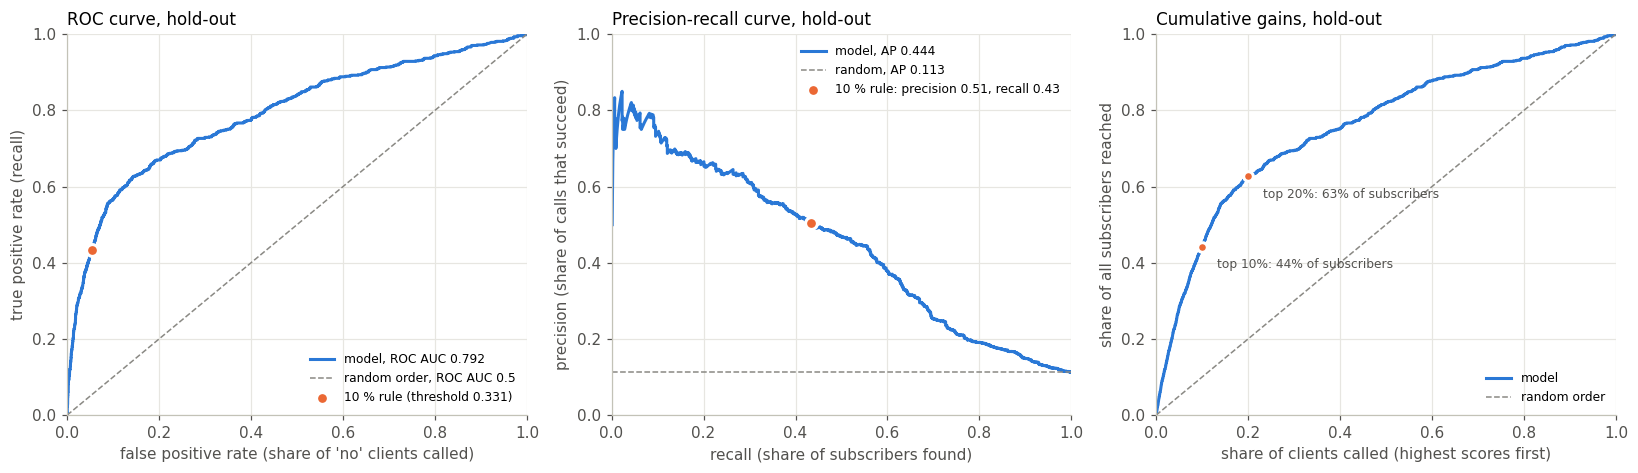

In [38]:
# Hold-out curves. Left: ROC. Middle: precision-recall. Right: share of all subscribers reached when calling the
# clients with the highest scores first (cumulative gains). The orange dot is the saved 10 % rule threshold.
fpr, tpr, _ = roc_curve(y_hold, p_hold)
hp, hr, _ = precision_recall_curve(y_hold, p_hold)
hp, hr = hp[hr > 0], hr[hr > 0]  # drop the points at recall 0, where precision is undefined
order = np.argsort(-p_hold)
reached = np.cumsum(y_hold.to_numpy()[order]) / y_hold.sum()
called = np.arange(1, len(order) + 1) / len(order)
chosen = at_threshold(y_hold, p_hold, THRESHOLD)
chosen_fpr = chosen["FP"] / (chosen["FP"] + chosen["TN"])
dot = dict(s=60, color=YES, zorder=3, edgecolor="white", linewidth=2)

fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(15, 4.4))
a0.plot(fpr, tpr, color=NO, linewidth=2, label=f"model, ROC AUC {hold_auc:.3f}")
a0.plot([0, 1], [0, 1], color=NEUTRAL, linewidth=1, linestyle="--", label="random order, ROC AUC 0.5")
a0.scatter([chosen_fpr], [chosen["recall"]], label=f"10 % rule (threshold {THRESHOLD:.3f})", **dot)
a0.set(xlabel="false positive rate (share of 'no' clients called)", ylabel="true positive rate (recall)",
       xlim=(0, 1), ylim=(0, 1))
a0.set_title("ROC curve, hold-out", loc="left")
a0.legend(loc="lower right", fontsize=8)

a1.plot(hr, hp, color=NO, linewidth=2, label=f"model, AP {hold_ap:.3f}")
a1.axhline(y_hold.mean(), color=NEUTRAL, linewidth=1, linestyle="--", label=f"random, AP {y_hold.mean():.3f}")
a1.scatter([chosen["recall"]], [chosen["precision"]],
           label=f"10 % rule: precision {chosen['precision']:.2f}, recall {chosen['recall']:.2f}", **dot)
a1.set(xlabel="recall (share of subscribers found)", ylabel="precision (share of calls that succeed)",
       xlim=(0, 1), ylim=(0, 1))
a1.set_title("Precision-recall curve, hold-out", loc="left")
a1.legend(loc="upper right", fontsize=8)

a2.plot(called, reached, color=NO, linewidth=2, label="model")
a2.plot([0, 1], [0, 1], color=NEUTRAL, linewidth=1, linestyle="--", label="random order")
for share in (0.1, 0.2):
    got = reached[int(share * len(order)) - 1]
    a2.scatter([share], [got], s=40, color=YES, zorder=3, edgecolor="white", linewidth=2)
    a2.annotate(f"top {share:.0%}: {got:.0%} of subscribers", (share, got), xytext=(10, -14),
                textcoords="offset points", fontsize=8, color="#52514e")
a2.set(xlabel="share of clients called (highest scores first)", ylabel="share of all subscribers reached",
       xlim=(0, 1), ylim=(0, 1))
a2.set_title("Cumulative gains, hold-out", loc="left")
a2.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

In [39]:
# Confusion matrix on the hold-out at the saved 10 % rule threshold, in call-centre terms
pd.DataFrame([[chosen["TP"], chosen["FP"]], [chosen["FN"], chosen["TN"]]],
             index=["called", "not called"], columns=["would subscribe (yes)", "would not subscribe (no)"])

,would subscribe (yes),would not subscribe (no)
called,322,315
not called,420,5531


**What the hold-out says**

- **Ranking quality.** Hold-out AP is **0.444** and ROC AUC **0.792**, about four times the base rate in AP. Both
  are below the cross-validation estimates (0.480 and 0.804). The gap, 0.036 AP, is about 1.5 times the fold-to-fold
  standard deviation. Part of it is noise: the hold-out has only 742 `yes`. Part of it is the optimism expected from
  picking the best of 40+ settings on the same folds (Part 6). **0.44 is the number to quote**, not 0.48.
- **The 10 % rule.** The saved threshold 0.331 calls 637 of the 6,588 hold-out clients (9.7 %). Ranking the hold-out
  itself and calling exactly its top 10 % (659 clients) gives almost the same result, so a threshold set on the
  development set carries over well. At the saved threshold precision is **0.505** against 0.113 when calling at
  random, a **lift of 4.5**, and recall is **0.434**: 43 % of all subscribers are reached with 10 % of the calls.
- **The confusion matrix for the call centre.** Out of 6,588 clients, the centre calls 637. 322 of those calls end
  in a deposit and 315 are wasted on clients who say no, so about every second call succeeds. 420 clients who would
  have subscribed are never called; that is the price of calling only 10 %. The other 5,531 clients are rightly left
  alone. Calling everyone would find all 742 subscribers but take more than ten times the calls.
- **Other thresholds.** The best-F1 threshold (0.211) calls 14 % and reaches 55 % of subscribers at lower precision
  (0.445); 0.5 calls only 4 % and reaches 24 %. They break the capacity rule in one direction or the other.
- **The gains curve** shows the same thing without a threshold: the top 10 % by score reach 44 % of the subscribers,
  the top 20 % reach 63 %.
- **How the random split flatters the result.** The hold-out is a random 20 % of the same 2008–2010 campaigns, so
  it shares the months and economic conditions the model learned from, and those are its strongest features. On
  next year's campaign, in a different economy, precision and lift would very likely be lower than here.

## Part 8 · Refit, save, reload and score `test.csv`

### Refit on all of `train.csv` and save

The model is chosen and measured, so the hold-out rows have done their job. The final model is refitted on all
32,940 labelled rows with the same settings. More data can only help, and there is nothing left to evaluate it on.

What is saved is one scikit-learn object, `model.joblib`:

- `FixedThresholdClassifier` (scikit-learn ≥ 1.5) wraps the pipeline, so `predict` applies the 10 % rule threshold of
  Part 7 instead of 0.5, and `predict_proba` still returns the probabilities.
- It is fitted on `y` coded as 1 = `yes`, 0 = `no`, so `predict` returns 0 / 1 and column 1 of `predict_proba` is the
  probability of `yes`.
- The pipeline selects its 19 columns by name, so it takes `test.csv` as it is, with `id` in it, and ignores
  anything else.

In [40]:
from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import FixedThresholdClassifier

MODEL_PATH = Path("model.joblib")

final_model = FixedThresholdClassifier(clone(final_pipe), threshold=THRESHOLD, pos_label=1,
                                       response_method="predict_proba")
final_model.fit(train[FEATURES], (train[TARGET] == "yes").astype(int))
joblib.dump(final_model, MODEL_PATH)

print("classes:", final_model.classes_.tolist(), "| threshold:", round(final_model.threshold, 4))
print("boosting iterations kept by early stopping:", final_model.estimator_[-1].n_iter_)
print(f"saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} KB)")

classes: [0, 1] | threshold: 0.3315
boosting iterations kept by early stopping: 155
saved model.joblib (297 KB)


### Reload and score `test.csv`

The real test of the saved file: load it in a **separate Python process** that has none of this notebook's
variables or functions, only the pinned libraries, and score the raw `test.csv`.

In [41]:
import subprocess

reload_check = '''
import joblib, pandas as pd
model = joblib.load("model.joblib")
test = pd.read_csv("data/test.csv")
pred = model.predict(test)
proba = model.predict_proba(test)[:, 1]
print(type(model).__name__, model.classes_.tolist(), len(pred), pd.Series(pred).value_counts().to_dict(),
      round(float(proba.mean()), 4))
'''
out = subprocess.run([sys.executable, "-c", reload_check], capture_output=True, text=True, check=True)
print(out.stdout.strip() or out.stderr)

FixedThresholdClassifier [0, 1] 8236 {0: 7452, 1: 784} 0.1102


In [42]:
# The same model, loaded here, writes the predictions file
model = joblib.load(MODEL_PATH)
test_pred = model.predict(test)
test_proba = model.predict_proba(test)[:, 1]

predictions = pd.DataFrame({"id": test["id"], "y_pred": test_pred, "y_score": test_proba})
predictions.to_csv("predictions.csv", index=False)

# The reloaded model gives exactly what the in-memory one gives, and y_pred is y_score cut at the threshold
assert (test_pred == final_model.predict(test)).all()
assert np.allclose(test_proba, final_model.predict_proba(test)[:, 1])
assert (test_pred == (test_proba >= THRESHOLD).astype(int)).all()

print(predictions.shape, "| ids match test.csv:", predictions["id"].equals(test["id"]))
print(predictions["y_pred"].value_counts().to_string())
print(f"share called on test {test_pred.mean():.3f} | mean y_score on test {test_proba.mean():.4f} | "
      f"train base rate {yes_rate:.4f}")
predictions.head()

(8236, 3) | ids match test.csv: True
y_pred
0    7452
1     784
share called on test 0.095 | mean y_score on test 0.1102 | train base rate 0.1127


,id,y_pred,y_score
0,32940,0,0.044482
1,32941,0,0.035107
2,32942,0,0.053962
3,32943,0,0.082524
4,32944,0,0.049187


**What the scoring says**

- The saved file loads in a fresh process with only `joblib` and `pandas` imported, takes the raw `test.csv`, and its
  predictions are identical to the in-memory model's.
- It predicts 1 (call) for 784 of the 8,236 test clients (9.5 %), close to the 10 % capacity and to the 9.7 % on the
  hold-out. The mean predicted probability, 0.110, is close to the base rate 0.113. There is no sign that `test.csv`
  looks different from the training data.
- `predictions.csv` has one row per test client: `id`, the decision `y_pred` (1 = call, at threshold 0.331) and the
  probability of `yes`, `y_score`.

## Conclusions

1. **Data.** 32,940 labelled calls, 11.3 % `yes`, no missing cells. Missing information is coded instead: `unknown`
   stays as its own category (`default = unknown`: 0.052 against 0.129; imputing it instead gives the same CV AP, so
   keeping it loses nothing), and `pdays = 999` becomes a flag plus −1. `duration` is left out because it is only
   known after the call, when the outcome is too, and `test.csv` does not have it.
2. **Model.** Gradient boosting (`HistGradientBoostingClassifier`, tuned by random search on average precision) inside
   one scikit-learn pipeline with its preprocessing. It beat tuned logistic regression on every fold, but only by
   about 0.02 AP. Tuned against default boosting (+0.004 AP, standard error 0.004) and boosting against random forest
   (0.476 both) are inside the fold noise, so there is no real winner there. Logistic regression is a reasonable,
   more interpretable runner-up.
3. **Performance.** Unbiased hold-out estimate: **AP 0.444, ROC AUC 0.792**, against 0.113 and 0.5 for guessing.
   Under the 10 % rule the model calls 9.7 % of hold-out clients, half of those calls succeed (precision 0.505, lift
   4.5 over calling at random) and it reaches 43 % of all subscribers.
4. **Deliverables.** `model.joblib` is the final model refitted on all of `train.csv`. It is a
   `FixedThresholdClassifier` with the 10 % rule threshold 0.331 that loads with the pinned libraries alone and
   predicts 0 / 1 straight from the raw `test.csv`. `predictions.csv` holds `id`, `y_pred` and `y_score` for the
   8,236 test clients.

**Limitations**

- The strongest signals, the economic indicators and the month, describe **when** a call was made more than **who**
  was called. `train.csv` and `test.csv` are a random split of the same 2008–2010 campaigns, so they share those
  periods. A model used on a new campaign in a different economic situation would very likely do worse than the
  numbers here. The data has no year column, so a split by time, the honest check for that, cannot be done.
- The 10 % rule fixes how many clients are called, not what a call costs or a deposit earns, which are not known.
- The predictions for `test.csv` cannot be checked here: it has no labels.
- This is a teaching dataset, not evidence about real banks or clients.

**Reproducibility.** Every split, fold, search and model uses SEED = 2954. The libraries are pinned in
`requirements.txt`, and *Restart & Run All* reproduces every number, the model file and `predictions.csv` in about a
minute on a laptop.